<a href="https://colab.research.google.com/github/ArifahZhafirah/PEMBELAJARAN-MESIN/blob/main/JS07/TUGAS-LAB/PEMMESTUGAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab JS07 - Klasterisasi Data Nasabah Kartu Kredit


## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

## Load dan Inspeksi Data

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


## Soal 1 - Scatterplot `Avg_Credit_Limit` dan `Total_Credit_Cards`
Catatan: nama kolom pada file adalah `Total_Credit_Cards`.

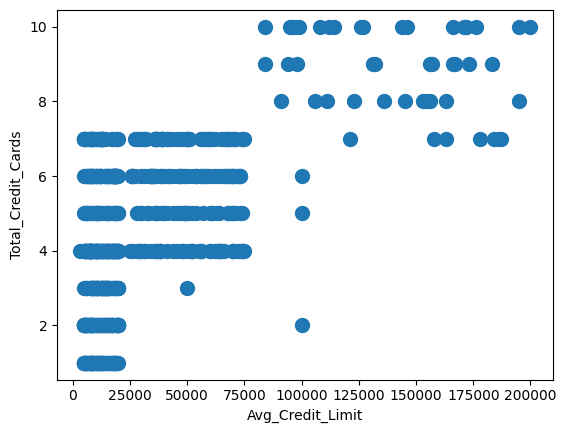

In [4]:
# Make a scatterplot using
# Avg_Credit_Limit and Total_Credit_Cards
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s = 100)

In [5]:
# Cek korelasi linier kedua variabel
print(df[['Avg_Credit_Limit', 'Total_Credit_Cards']].corr())

                    Avg_Credit_Limit  Total_Credit_Cards
Avg_Credit_Limit             1.00000             0.60886
Total_Credit_Cards           0.60886             1.00000


**Analisis:** Sebaran data tidak dapat dikatakan linier. Titik-titik tidak membentuk satu garis lurus yang jelas. Jumlah kartu kredit hanya berupa bilangan bulat 1 sampai 10 sehingga titik tersusun dalam baris-baris horizontal, dan pada limit kredit rendah (di bawah sekitar 50.000) jumlah kartu bervariasi dari 1 sampai 7 tanpa pola garis. Nilai korelasi Pearson sekitar 0,61 (korelasi positif sedang, bukan hubungan linier yang kuat). Pada limit kredit tinggi (100.000 ke atas), sebagian besar nasabah memiliki 7 sampai 10 kartu dan terlihat membentuk kelompok tersendiri. Hal ini mengindikasikan data cenderung membentuk kelompok (cluster) sehingga cocok untuk klasterisasi.

## Seleksi Fitur dan Standardisasi
Kolom `Sl_No` dan `Customer Key` hanya pengenal (ID) sehingga tidak dipakai sebagai fitur. Karena skala `Avg_Credit_Limit` (puluhan ribu) jauh berbeda dengan variabel lain (0-15), dilakukan standardisasi dengan `StandardScaler` seperti pada modul JS02 Lab 3.

In [6]:
# Features Selection
X_all = df.iloc[:, 2:] # Sl_No dan Customer Key tidak dipakai
print(X_all.head())

   Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
0            100000                   2                  1   
1             50000                   3                  0   
2             50000                   7                  1   
3             30000                   5                  1   
4            100000                   6                  0   

   Total_visits_online  Total_calls_made  
0                    1                 0  
1                   10                 9  
2                    3                 4  
3                    1                 4  
4                   12                 3  


In [7]:
std = StandardScaler()
X_all_std = std.fit_transform(X_all)

# Dua variabel untuk soal 2 dan 3
X = pd.DataFrame(std.fit_transform(df[['Avg_Credit_Limit', 'Total_Credit_Cards']]),
                 columns=['Avg_Credit_Limit', 'Total_Credit_Cards'])
X.head()

,Avg_Credit_Limit,Total_Credit_Cards
0,1.740187,-1.249225
1,0.410293,-0.787585
2,0.410293,1.058973
3,-0.121665,0.135694
4,1.740187,0.597334


## Soal 2 - K-Means dan Elbow Method (k terbaik)

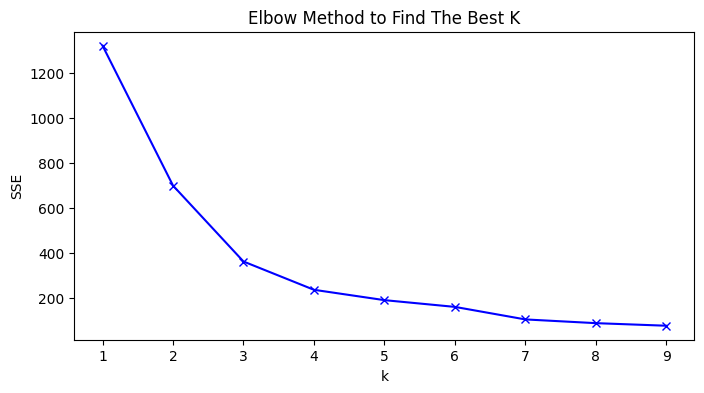

In [8]:
# Find the best k
# using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1,10)

# Find the SSE value for each k
for k in K:
 kmeanModel = KMeans(n_clusters=k, random_state=0)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

In [9]:
print(sse)

[1319.9999999999995, 698.2933315506664, 361.09282133501557, 235.39274939690915, 189.40665033693884, 159.44845634852686, 103.73112607158578, 87.16983099417615, 75.73241481714865]


**Analisis:** SSE turun sangat tajam dari k=1 (sekitar 1320) ke k=2 (sekitar 698) dan k=3 (sekitar 361). Setelah k=3 penurunannya jauh lebih landai (k=4 sekitar 235, k=5 sekitar 189) dan terus melandai. (Nilai bisa sedikit berbeda karena posisi centroid awal acak.) Titik tekuk (elbow) berada di **k = 3**. Nilai k yang lebih besar memang membuat SSE lebih kecil, tetapi itu terjadi karena cluster semakin sempit, bukan karena model lebih baik. Jadi dipilih k = 3.

## Soal 3 - Hasil Klasterisasi K-Means (k = 3)

In [10]:
# Build a K-Means Model
cl_kmeans = KMeans(n_clusters=3, random_state=0)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

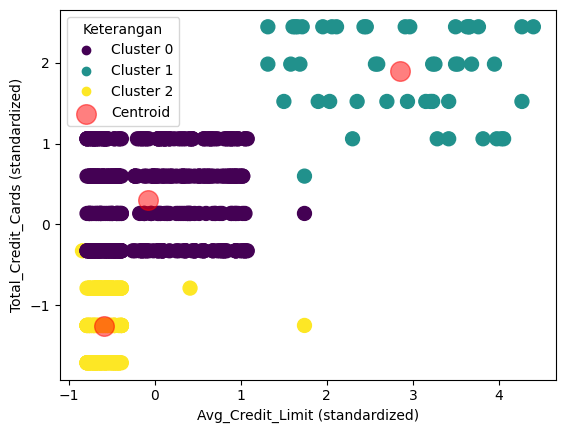

In [11]:
# Plot the clustering result
plt.xlabel('Avg_Credit_Limit (standardized)')
plt.ylabel('Total_Credit_Cards (standardized)')
scatter = plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot the centroid
centers = cl_kmeans.cluster_centers_
cent = plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

# Keterangan warna
handles, _ = scatter.legend_elements()
plt.legend(handles + [cent], ['Cluster 0', 'Cluster 1', 'Cluster 2', 'Centroid'], title='Keterangan')

In [12]:
# Rata-rata tiap cluster (nilai asli) untuk membantu menjelaskan karakteristik cluster
print(df.groupby(y_kmeans)[['Avg_Credit_Limit', 'Total_Credit_Cards']].agg(['mean', 'count']))

  Avg_Credit_Limit       Total_Credit_Cards      
              mean count               mean count
0     31426.267281   434           5.354839   434
1    141877.551020    49           8.816327    49
2     12587.570621   177           1.977401   177


In [13]:
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 361.09282133501557


## Soal 4 - DBSCAN dengan seluruh variabel yang dapat digunakan
Variabel yang dipakai: `Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, `Total_calls_made` (kolom ID tidak dipakai). Parameter eps ditentukan pada Soal 5, sehingga bagian ini dijalankan setelah Soal 5 (eps = 1.0, min_samples = 5).

In [14]:
dbscan = DBSCAN(eps=1.0, min_samples=5)
cluster_db = dbscan.fit_predict(X_all_std)

print('Label cluster:', np.unique(cluster_db))
print('Jumlah data noise:', (cluster_db == -1).sum())
print('Persentase noise:', (cluster_db == -1).sum() / len(cluster_db) * 100, '%')

Label cluster: [-1  0  1]
Jumlah data noise: 18
Persentase noise: 2.727272727272727 %


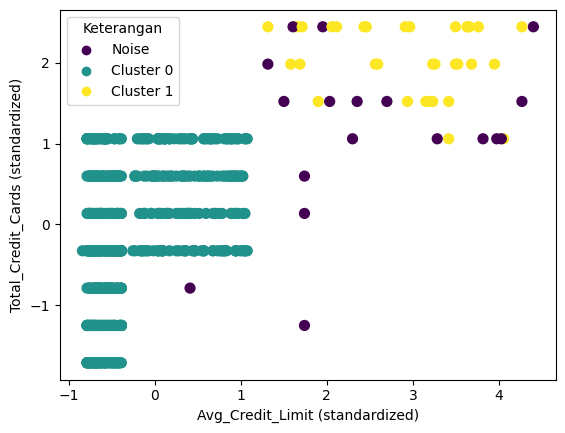

In [15]:
# Visualisasi hasil DBSCAN (2 dari 5 variabel agar dapat diplot)
plt.xlabel('Avg_Credit_Limit (standardized)')
plt.ylabel('Total_Credit_Cards (standardized)')
scatter_db = plt.scatter(X_all_std[:, 0], X_all_std[:, 1], c=cluster_db, s=50, cmap='viridis')

# Keterangan warna (label -1 = noise)
handles, _ = scatter_db.legend_elements()
labels = ['Noise' if l == -1 else f'Cluster {l}' for l in np.unique(cluster_db)]
plt.legend(handles, labels, title='Keterangan')

## Soal 5 - Menentukan eps DBSCAN dengan metode elbow (k-distance graph)
Pada DBSCAN tidak ada jumlah cluster yang ditentukan di awal. Sesuai teori pada modul, parameter eps dipilih dengan mencari titik "siku" (knee) pada grafik jarak nearest neighbor.

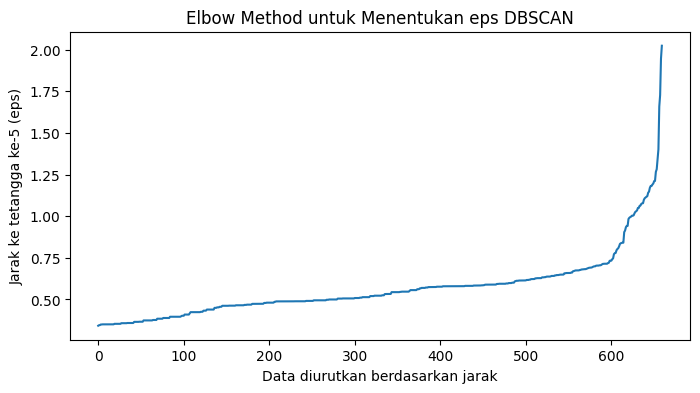

In [16]:
from sklearn.neighbors import NearestNeighbors

# Jarak ke tetangga ke-5 (sesuai min_samples = 5)
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_all_std)
distances, indices = neighbors_fit.kneighbors(X_all_std)

# Urutkan jarak ke tetangga terjauh (ke-5)
distances = np.sort(distances[:, -1])

plt.figure(figsize=(8,4))
plt.plot(distances)
plt.xlabel('Data diurutkan berdasarkan jarak')
plt.ylabel('Jarak ke tetangga ke-5 (eps)')
plt.title('Elbow Method untuk Menentukan eps DBSCAN')
plt.show()

In [17]:
print(np.round(distances[[500, 560, 600, 620, 640, 650, 659]], 2))

[0.61 0.67 0.73 0.98 1.11 1.21 2.02]


**Analisis:** Sebagian besar data (sekitar 85-90%) memiliki jarak ke tetangga ke-5 di bawah sekitar 0,9 sehingga kurvanya landai. Mulai sekitar nilai **1,0** kurva naik tajam (siku). Data di atas titik ini adalah data yang terisolasi (calon noise). Jika eps dibuat lebih kecil (misalnya 0,5) hampir semua data menjadi noise, sedangkan jika terlalu besar (misalnya 2,0) seluruh data menyatu menjadi satu cluster. Oleh karena itu dipilih **eps = 1.0** dengan min_samples = 5.

## Soal 6 - Silhouette Score dan DBI dari DBSCAN

In [18]:
print(silhouette_score(X_all_std, cluster_db))

0.5212158436066416


In [19]:
# Compute and print Davies-Bouldin Index
db = davies_bouldin_score(X_all_std, cluster_db)

print(f"Davies-Bouldin Index: {db}")

Davies-Bouldin Index: 2.161286549531624


**Analisis:** Silhouette score sekitar 0,52 (cukup baik karena di atas 0,5) sedangkan DBI sekitar 2,16 (relatif tinggi, semakin kecil semakin baik). Keduanya perlu dibaca hati-hati karena DBSCAN menghasilkan 2 cluster saja dengan satu cluster sangat dominan (sekitar 608 data) ditambah 18 data noise (label -1) yang ikut dihitung sebagai satu kelompok oleh fungsi metrik.